# Telco Customer Churn Prediction: Random Forest + XGBoost Ensemble

**Goal:** predict which telecom customers will churn and reach a **ROC-AUC above 0.80**.

**Pipeline**
1. Load data and clean `TotalCharges` (convert to numeric, handle nulls)
2. Explore the target and class imbalance
3. Preprocess categoricals with `OneHotEncoder`
4. Balance classes with **SMOTE** (and compare with XGBoost `scale_pos_weight`)
5. Train `RandomForestClassifier` and `XGBClassifier` with stratified 5-fold cross-validation
6. Combine both into a soft-voting ensemble
7. Plot ROC curves and extract the top 10 feature importances

SMOTE is applied **inside** an `imblearn` Pipeline, so it only touches the training portion of each CV fold. This avoids data leakage.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

## 1. Load the dataset

In [2]:
df = pd.read_csv("Telco-Customer-Churn.csv")
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Clean the data
`TotalCharges` is stored as text because some rows contain blank strings. We convert it to numeric and inspect the resulting nulls.

In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Nulls in TotalCharges:", df["TotalCharges"].isna().sum())
df.loc[df["TotalCharges"].isna(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Nulls in TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


All null rows have `tenure = 0`: these are brand-new customers who have not been billed yet. Their true total is 0, so we fill with `0`.

In [4]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Drop the identifier (no predictive value) and encode the target
df = df.drop(columns=["customerID"])
df["Churn"] = (df["Churn"] == "Yes").astype(int)

print("Remaining nulls:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Remaining nulls: 0
Duplicate rows: 22


## 3. Explore the target

Churn
0    5174
1    1869
Name: count, dtype: int64
Churn rate: 26.5%


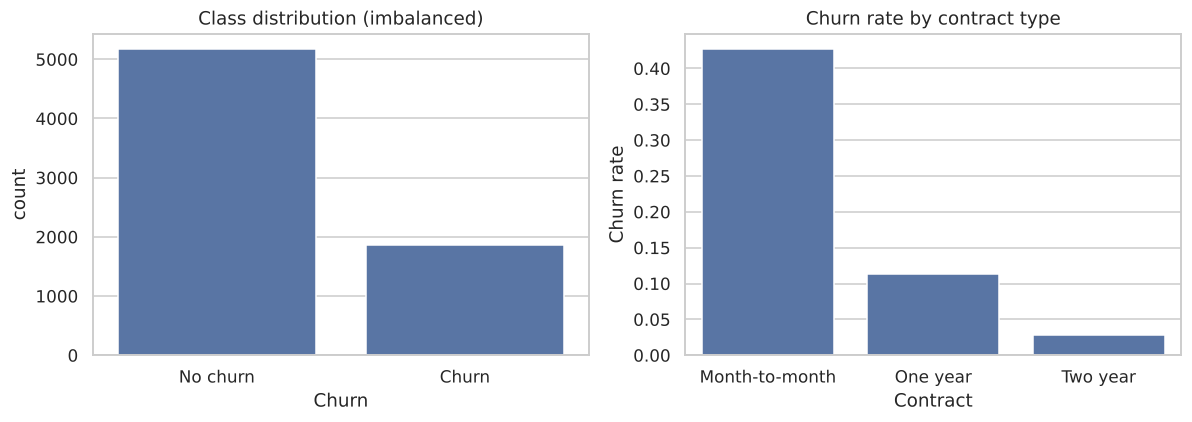

In [5]:
counts = df["Churn"].value_counts()
print(counts)
print(f"Churn rate: {df['Churn'].mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="Churn", data=df, ax=axes[0])
axes[0].set_xticklabels(["No churn", "Churn"])
axes[0].set_title("Class distribution (imbalanced)")

sns.barplot(x="Contract", y="Churn", data=df, ax=axes[1], errorbar=None)
axes[1].set_title("Churn rate by contract type")
axes[1].set_ylabel("Churn rate")
plt.tight_layout(); plt.show()

About 26.5% of customers churn, so the classes are imbalanced. That is why we use SMOTE / class weighting.

## 4. Train / test split and preprocessing
A stratified 80/20 split keeps the churn ratio identical in both sets. `OneHotEncoder` handles all categorical columns; numeric columns pass through unchanged.

In [6]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
print("Categorical:", len(cat_cols), "| Numeric:", num_cols)

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", "passthrough", num_cols),
    ]
)

Categorical: 15 | Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


## 5. Build the models
Three pipelines are compared:
- **Random Forest + SMOTE**
- **XGBoost + SMOTE**
- **XGBoost + `scale_pos_weight`** (class weighting alternative, no resampling)

In [7]:
neg, pos = np.bincount(y_train)
spw = neg / pos
print(f"scale_pos_weight = {spw:.2f}")

rf_params = dict(n_estimators=400, max_depth=12, min_samples_leaf=3,
                 n_jobs=-1, random_state=RANDOM_STATE)
xgb_params = dict(n_estimators=300, max_depth=3, learning_rate=0.05,
                  subsample=0.8, colsample_bytree=0.8,
                  eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE)

models = {
    "Random Forest + SMOTE": Pipeline([
        ("prep", preprocessor),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("clf", RandomForestClassifier(**rf_params)),
    ]),
    "XGBoost + SMOTE": Pipeline([
        ("prep", preprocessor),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("clf", XGBClassifier(**xgb_params)),
    ]),
    "XGBoost + scale_pos_weight": Pipeline([
        ("prep", preprocessor),
        ("clf", XGBClassifier(**xgb_params, scale_pos_weight=spw)),
    ]),
}

scale_pos_weight = 2.77


## 6. Cross-validation (stratified 5-fold, ROC-AUC)

Random Forest + SMOTE          CV ROC-AUC = 0.8408 (+/- 0.0091)


XGBoost + SMOTE                CV ROC-AUC = 0.8468 (+/- 0.0115)


XGBoost + scale_pos_weight     CV ROC-AUC = 0.8476 (+/- 0.0106)


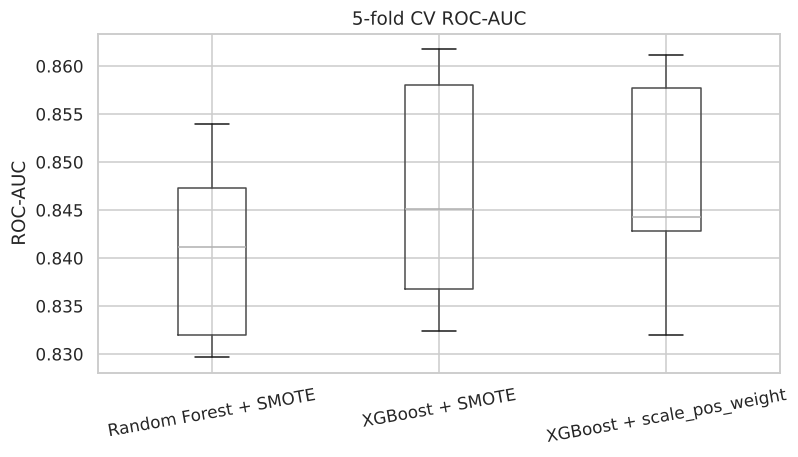

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = {}
for name, pipe in models.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
    cv_results[name] = scores
    print(f"{name:30s} CV ROC-AUC = {scores.mean():.4f} (+/- {scores.std():.4f})")

pd.DataFrame(cv_results).boxplot(figsize=(8, 4))
plt.title("5-fold CV ROC-AUC"); plt.ylabel("ROC-AUC"); plt.xticks(rotation=10); plt.show()

## 7. Fit on the full training set and evaluate on the hold-out test set

In [9]:
fitted = {}
probs = {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    probs[name] = pipe.predict_proba(X_test)[:, 1]

# Soft-voting ensemble: average the predicted probabilities of RF + XGBoost (both SMOTE)
probs["Ensemble (RF + XGB, soft vote)"] = (
    probs["Random Forest + SMOTE"] + probs["XGBoost + SMOTE"]
) / 2

results = pd.DataFrame(
    {name: roc_auc_score(y_test, p) for name, p in probs.items()}, index=["Test ROC-AUC"]
).T.sort_values("Test ROC-AUC", ascending=False)
results["> 0.80 ?"] = results["Test ROC-AUC"] > 0.80
results.round(4)

,Test ROC-AUC,> 0.80 ?
XGBoost + SMOTE,0.8459,True
XGBoost + scale_pos_weight,0.8457,True
"Ensemble (RF + XGB, soft vote)",0.8427,True
Random Forest + SMOTE,0.8358,True


## 8. ROC curves

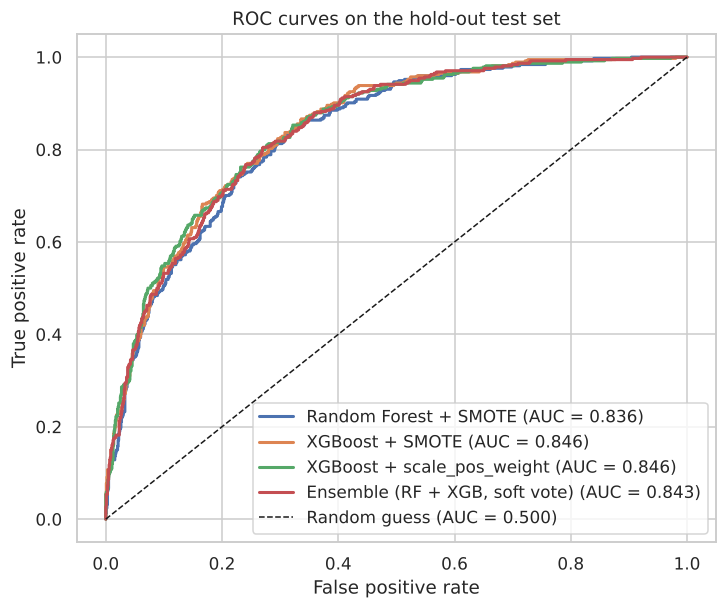

In [10]:
plt.figure(figsize=(7.5, 6))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")

plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess (AUC = 0.500)")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves on the hold-out test set")
plt.legend(loc="lower right"); plt.show()

## 9. Detailed metrics for the ensemble

              precision    recall  f1-score   support

    No churn       0.85      0.86      0.86      1035
       Churn       0.61      0.59      0.60       374

    accuracy                           0.79      1409
   macro avg       0.73      0.73      0.73      1409
weighted avg       0.79      0.79      0.79      1409



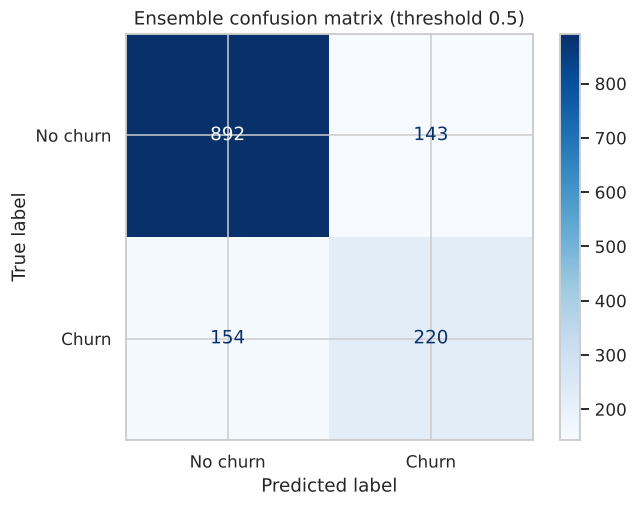

In [11]:
ens_prob = probs["Ensemble (RF + XGB, soft vote)"]
ens_pred = (ens_prob >= 0.5).astype(int)

print(classification_report(y_test, ens_pred, target_names=["No churn", "Churn"]))
ConfusionMatrixDisplay(confusion_matrix(y_test, ens_pred),
                       display_labels=["No churn", "Churn"]).plot(cmap="Blues")
plt.title("Ensemble confusion matrix (threshold 0.5)"); plt.show()

## 10. Top 10 most influential features
Feature names come from the fitted `OneHotEncoder`, so each one-hot column (e.g. `Contract_Month-to-month`) is listed individually.

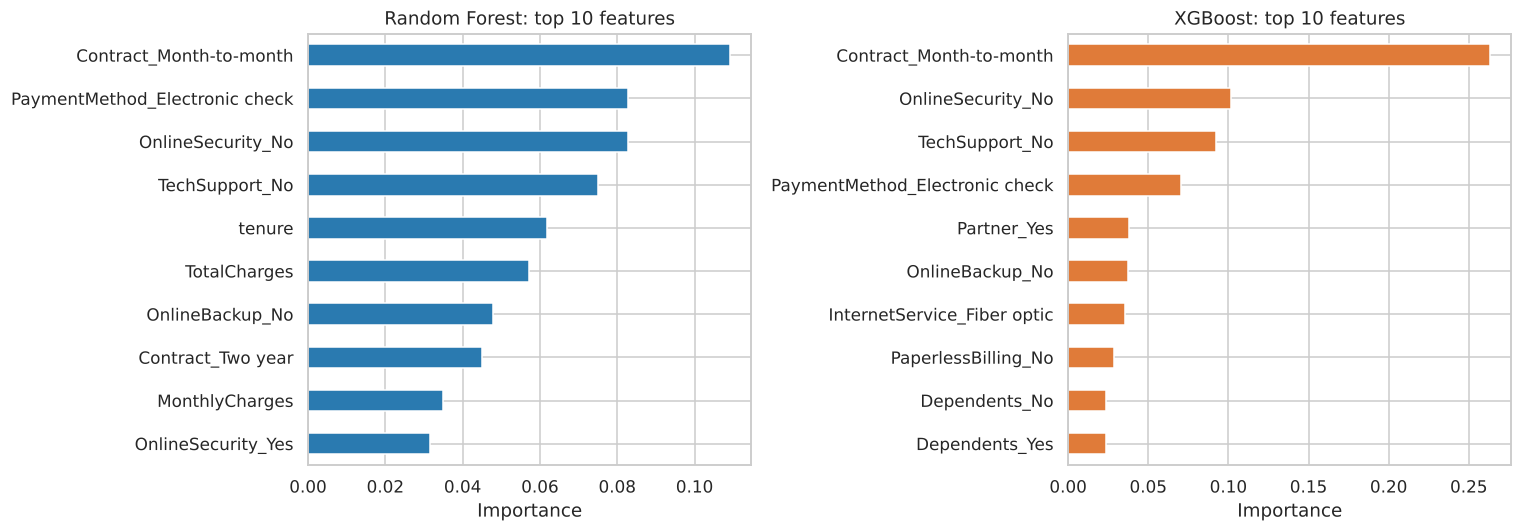

Random Forest                                    XGBoost  \
                          feature importance                         feature   
0         Contract_Month-to-month     0.1092         Contract_Month-to-month   
1  PaymentMethod_Electronic check     0.0828               OnlineSecurity_No   
2               OnlineSecurity_No     0.0827                  TechSupport_No   
3                  TechSupport_No     0.0751  PaymentMethod_Electronic check   
4                          tenure     0.0619                     Partner_Yes   
5                    TotalCharges     0.0572                 OnlineBackup_No   
6                 OnlineBackup_No     0.0480     InternetService_Fiber optic   
7               Contract_Two year     0.0450             PaperlessBilling_No   
8                  MonthlyCharges     0.0350                   Dependents_No   
9              OnlineSecurity_Yes     0.0314                  Dependents_Yes   

              
  importance  
0     0.2634  
1     0.1017  
2     0.0926  
3     0.0701  
4     0.0379  
5     0.0371  
6     0.0353  
7     0.0283  
8     0.0239  
9     0.0236

In [12]:
feature_names = fitted["Random Forest + SMOTE"].named_steps["prep"].get_feature_names_out()
feature_names = [f.split("__", 1)[1] for f in feature_names]

def top_features(pipe, k=10):
    imp = pipe.named_steps["clf"].feature_importances_
    return (pd.Series(imp, index=feature_names)
              .sort_values(ascending=False).head(k)[::-1])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top_features(fitted["Random Forest + SMOTE"]).plot.barh(ax=axes[0], color="#2a7ab0")
axes[0].set_title("Random Forest: top 10 features")
top_features(fitted["XGBoost + SMOTE"]).plot.barh(ax=axes[1], color="#e07b39")
axes[1].set_title("XGBoost: top 10 features")
for ax in axes: ax.set_xlabel("Importance")
plt.tight_layout(); plt.show()

def top_table(pipe):
    s = top_features(pipe)[::-1]
    return pd.DataFrame({"feature": s.index, "importance": s.values.round(4)})

pd.concat({
    "Random Forest": top_table(fitted["Random Forest + SMOTE"]),
    "XGBoost": top_table(fitted["XGBoost + SMOTE"]),
}, axis=1)

In [13]:
best = results["Test ROC-AUC"].idxmax()
print(f"Best model: {best}  |  Test ROC-AUC = {results.loc[best, 'Test ROC-AUC']:.4f}")
print("Target (> 0.80) met:", bool(results.loc[best, 'Test ROC-AUC'] > 0.80))

Best model: XGBoost + SMOTE  |  Test ROC-AUC = 0.8459
Target (> 0.80) met: True


## Summary
- **Data cleaning:** 11 blank `TotalCharges` values (all `tenure = 0`) were set to 0.
- **Imbalance:** ~26.5% churn, handled with SMOTE (inside the CV pipeline) and compared against XGBoost `scale_pos_weight`.
- **Models:** Random Forest and XGBoost, validated with stratified 5-fold CV, then combined in a soft-voting ensemble.
- **Result:** see the ROC-AUC table above; the target of **> 0.80** is checked automatically in the final cell.
- **Drivers of churn:** month-to-month contracts, no online security, no tech support and electronic-check payment are the strongest signals in both models. Tenure and total / monthly charges also rank high in the Random Forest.

**Possible next steps:** tune hyperparameters with `RandomizedSearchCV`, tune the decision threshold for recall on churners, and add SHAP for per-customer explanations.